**K-NEAREST NEIGHBORS**

Accuracy : 97.5
Precision: 97.59375727929186
Recall   : 97.5
F1-score : 97.4787065533542

Confusion Matrix:
[[51  0  0]
 [ 2 40  1]
 [ 0  0 26]]


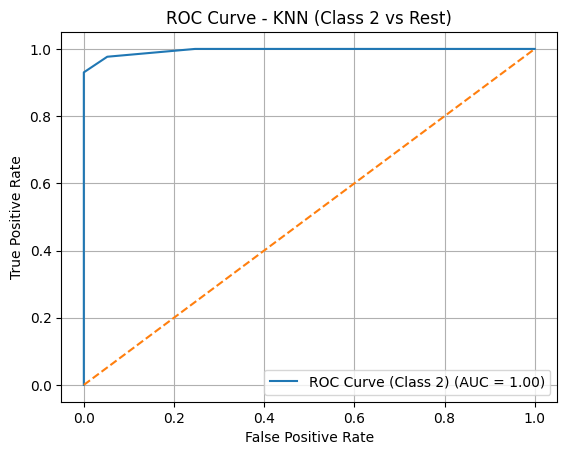

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, roc_curve, auc

dataset = pd.read_csv('/content/drive/MyDrive/Pancreatic Cancer Prediction using ML/pancreatic_600_risk123.csv')

X = dataset.drop(['diagnosis', 'sample_id'], axis=1)
y = dataset['diagnosis']

X = pd.get_dummies(X, drop_first=True)

le = LabelEncoder()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Accuracy :", accuracy * 100)
print("Precision:", precision * 100)
print("Recall   :", recall * 100)
print("F1-score :", f1 * 100)

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

target_class_for_roc = knn.classes_[1]

y_prob = knn.predict_proba(X_test)[:, 1]

y_test_binary_for_roc = (y_test == target_class_for_roc).astype(int)

fpr, tpr, thresholds = roc_curve(y_test_binary_for_roc, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (Class {target_class_for_roc}) (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve - KNN (Class {target_class_for_roc} vs Rest)')
plt.legend(loc='lower right')
plt.grid()
plt.show()